In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/jangedoo/utkface-new/UTKFace/100_0_0_20170112213500903.jpg.chip.jpg
/kaggle/input/datasets/jangedoo/utkface-new/UTKFace/100_0_0_20170112215240346.jpg.chip.jpg
/kaggle/input/datasets/jangedoo/utkface-new/UTKFace/100_1_0_20170110183726390.jpg.chip.jpg
/kaggle/input/datasets/jangedoo/utkface-new/UTKFace/100_1_0_20170112213001988.jpg.chip.jpg
/kaggle/input/datasets/jangedoo/utkface-new/UTKFace/100_1_0_20170112213303693.jpg.chip.jpg
/kaggle/input/datasets/jangedoo/utkface-new/UTKFace/100_1_0_20170112215032192.jpg.chip.jpg
/kaggle/input/datasets/jangedoo/utkface-new/UTKFace/100_1_0_20170117195420803.jpg.chip.jpg
/kaggle/input/datasets/jangedoo/utkface-new/UTKFace/100_1_0_20170119212053665.jpg.chip.jpg
/kaggle/input/datasets/jangedoo/utkface-new/UTKFace/100_1_2_20170105174847679.jpg.chip.jpg
/kaggle/input/datasets/jangedoo/utkface-new/UTKFace/100_1_2_20170112213615815.jpg.chip.jpg
/kaggle/input/datasets/jangedoo/utkface-new/UTKFace/100_1_2_20170112222336458.jpg.chip.jpg

In [17]:
import os

data_dir = "/kaggle/input/datasets/jangedoo/utkface-new"

print(os.listdir(data_dir))

['UTKFace', 'crop_part1', 'utkface_aligned_cropped']


In [18]:
import os
import pandas as pd

data_dir = "/kaggle/input/datasets/jangedoo/utkface-new"

image_paths = []
ages = []

for root, dirs, files in os.walk(data_dir):

    for filename in files:

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            parts = filename.split("_")

            if len(parts) >= 4 and parts[0].isdigit():

                age = int(parts[0])

                image_path = os.path.join(root, filename)

                image_paths.append(image_path)
                ages.append(age)

df = pd.DataFrame({"image_path": image_paths,"age": ages})

print("Total images:", len(df))
print(df.head())

Total images: 66966
                                          image_path  age
0  /kaggle/input/datasets/jangedoo/utkface-new/UT...  100
1  /kaggle/input/datasets/jangedoo/utkface-new/UT...  100
2  /kaggle/input/datasets/jangedoo/utkface-new/UT...  100
3  /kaggle/input/datasets/jangedoo/utkface-new/UT...  100
4  /kaggle/input/datasets/jangedoo/utkface-new/UT...  100


In [13]:
print(df.shape)
print(df["age"].describe())
print(df["age"].value_counts().sort_index())

(66966, 2)
count    66966.000000
mean        32.166144
std         21.501580
min          1.000000
25%         18.000000
50%         28.000000
75%         45.000000
max        116.000000
Name: age, dtype: float64
age
1      4470
2      1914
3      1146
4      1066
5       752
       ... 
105      10
110      14
111       2
115       6
116       8
Name: count, Length: 104, dtype: int64


Minimum age: 1
Maximum age: 116
count    66966.000000
mean        32.166144
std         21.501580
min          1.000000
25%         18.000000
50%         28.000000
75%         45.000000
max        116.000000
Name: age, dtype: float64


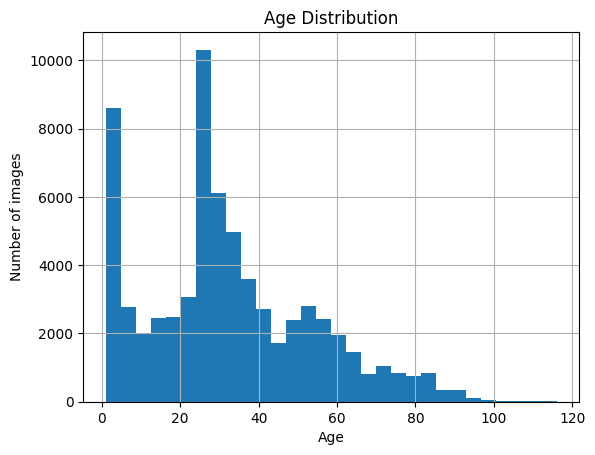

In [18]:
print("Minimum age:", df["age"].min())
print("Maximum age:", df["age"].max())

print(df["age"].describe())

df["age"].hist(bins=30)
plt.xlabel("Age")
plt.ylabel("Number of images")
plt.title("Age Distribution")
plt.show()

In [43]:
import tensorflow as tf
import numpy as np
import random

# Set random seeds
tf.random.set_seed(42)
np.random.seed(42)
random.seed(42)

In [44]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df,test_size=0.2,random_state=42)
train_df, val_df = train_test_split(train_df,test_size=0.2,random_state=42)

In [45]:
# now i need to read the images, ill use tensor flow
import tensorflow as tf
image_size = 48
batch_size = 32
def load_image(image_path, age):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(image,channels=3)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [image_size, image_size])
    image = image / 255
    return image, tf.cast(age, tf.float32)

In [46]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_df["image_path"].values, train_df["age"].values)
)

train_ds = train_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.shuffle(1000).batch(batch_size).prefetch(
    tf.data.AUTOTUNE
)

In [47]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_df["image_path"].values, test_df["age"].values)
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(batch_size).prefetch(
    tf.data.AUTOTUNE
)

In [48]:
val_ds = tf.data.Dataset.from_tensor_slices(
    (val_df["image_path"].values, val_df["age"].values)
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.batch(batch_size).prefetch(
    tf.data.AUTOTUNE
)

In [35]:
for images, ages in train_ds.take(1):

    print("Images shape:", images.shape)
    print("Ages shape:", ages.shape)

    print("First 5 ages:", ages[:5].numpy())

Images shape: (32, 48, 48, 3)
Ages shape: (32,)
First 5 ages: [21. 13. 29. 85. 66.]


In [38]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D

model = Sequential()
model.add(Conv2D(filters=30,
                 kernel_size=(3, 3),
                 activation="relu",
                 input_shape=(48, 48, 3)))

model.add(Conv2D(filters=40,
                 kernel_size=(3, 3),
                 activation="relu"))

model.add(Conv2D(filters=50,
                 kernel_size=(3, 3),
                 activation="relu"))
model.add(Flatten())

model.add(Dense(64, activation="relu"))
model.add(Dense(1))

model.compile(optimizer="adam",loss="mean_squared_error",metrics=["mae"])

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_11 (Conv2D)              │ (None, 46, 46, 30)     │           840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 44, 44, 40)     │        10,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 42, 42, 50)     │        18,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 88200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │     5,644,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,674,659 (21.65 MB)

 Trainable params: 5,674,659 (21.65 MB)

 Non-trainable params: 0 (0.00 B)

In [41]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D

model = Sequential()

# Feature extraction: learn patterns from images
model.add(Conv2D(filters=30,
                 kernel_size=(3, 3),
                 activation="relu",
                 input_shape=(48, 48, 3)))

model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(filters=40,
                 kernel_size=(3, 3),
                 activation="relu"))

model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(filters=50,
                 kernel_size=(3, 3),
                 activation="relu"))
model.add(Flatten())
model.add(Dense(64, activation="relu"))

# Predict age
model.add(Dense(1))

model.compile(loss="mean_squared_error",metrics=["mae"])

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)              │ (None, 46, 46, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │       409,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 429,121 (1.64 MB)

 Trainable params: 429,121 (1.64 MB)

 Non-trainable params: 0 (0.00 B)

In [42]:
history = model.fit(train_ds,epochs=10,validation_data=val_ds)

Epoch 1/10
1340/1340 ━━━━━━━━━━━━━━━━━━━━ 41s 29ms/step - loss: 256.1452 - mae: 11.9627 - val_loss: 166.2951 - val_mae: 9.2336
Epoch 2/10
1340/1340 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - loss: 144.9826 - mae: 8.8365 - val_loss: 120.0486 - val_mae: 8.1337
Epoch 3/10
1340/1340 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - loss: 114.1811 - mae: 7.8031 - val_loss: 114.9308 - val_mae: 8.2343
Epoch 4/10
1340/1340 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - loss: 100.6918 - mae: 7.3415 - val_loss: 102.8634 - val_mae: 7.4855
Epoch 5/10
1340/1340 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - loss: 88.9705 - mae: 6.8982 - val_loss: 87.1834 - val_mae: 6.9328
Epoch 6/10
1340/1340 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - loss: 79.3732 - mae: 6.5081 - val_loss: 92.7626 - val_mae: 7.1878
Epoch 7/10
1340/1340 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - loss: 71.3455 - mae: 6.1835 - val_loss: 73.3489 - val_mae: 6.2266
Epoch 8/10
1340/1340 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - loss: 63.1677 - mae: 5.8239 - val_loss: 78.0525 - val_mae: 6.5016

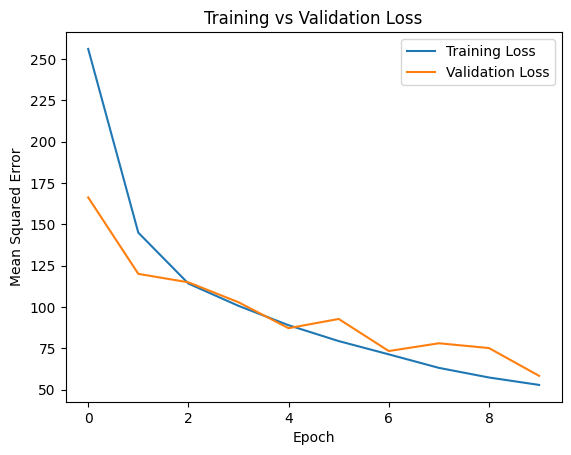

In [49]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

In [50]:
y_pred = model.predict(test_ds)

419/419 ━━━━━━━━━━━━━━━━━━━━ 292s 695ms/step


In [51]:
y_test = np.concatenate([ages.numpy() for images, ages in test_ds])

In [52]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_test, y_pred.flatten())

rmse = np.sqrt(mean_squared_error(y_test, y_pred.flatten()))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 5.516618728637695
RMSE: 7.582220170479293


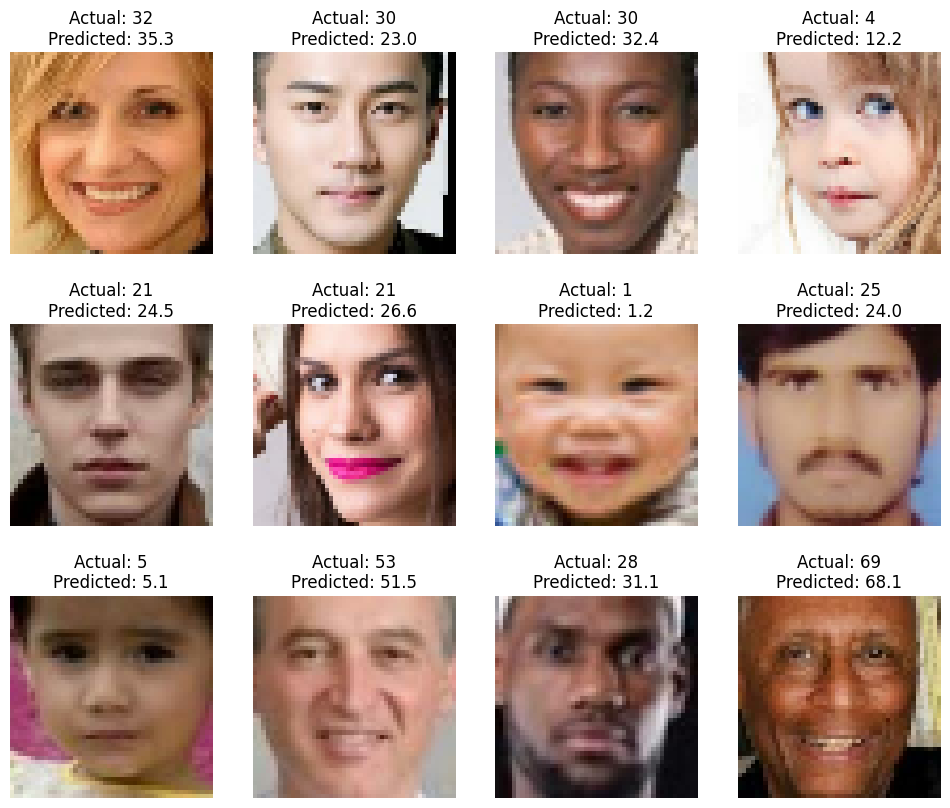

In [55]:
plt.figure(figsize=(12, 10))

for i, (images, ages) in enumerate(test_ds.take(1)):
    for j in range(12):
        plt.subplot(3, 4, j + 1)
        plt.imshow(images[j])
        plt.title(f"Actual: {y_test[j]:.0f}\nPredicted: {y_pred[j][0]:.1f}")
        plt.axis("off")

plt.show()

In [44]:
model.save("age-model.keras")